<a href="https://colab.research.google.com/github/KwancheolShin/introduction-to-deep-learning/blob/main/%ED%95%99%EC%8A%B5%EA%B4%80%EB%A0%A8%EA%B8%B0%EC%88%A0%EB%93%A4/code/mnist_numpy_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 학습 관련 기술: NumPy로 만든 최종 MNIST 분류기

He 초기화, 배치 정규화, AdamW, 검증 정확도로 epoch 고르기를 모두 쓴 NumPy network. 원본: `mnist_numpy_final.py`

* 셀을 위에서부터 차례로 실행한다 (Shift+Enter). 앞 셀에서 만든 변수는 다음 셀에서 그대로 쓸 수 있다.
* 그림은 작업 폴더의 `figures/`에도 저장된다 (Colab의 작업 폴더는 `/content`이며, 세션이 끝나면 지워진다).


이 노트북은 같은 폴더의 모듈 `mnist_data.py`, `layers.py`, `optimizers.py`을 불러 쓴다. 아래 셀은 그 파일이 없으면 (Colab처럼) 수업 GitHub 저장소에서 내려받는다.

In [1]:
import os, urllib.request, urllib.parse
REPO = "https://raw.githubusercontent.com/KwancheolShin/introduction-to-deep-learning/main/"
for f in ['mnist_data.py', 'layers.py', 'optimizers.py']:
    if not os.path.exists(f):
        urllib.request.urlretrieve(REPO + urllib.parse.quote("학습관련기술들/code/" + f), f)
        print("downloaded", f)
print("ready:", [f for f in ['mnist_data.py', 'layers.py', 'optimizers.py'] if os.path.exists(f)])

downloaded mnist_data.py


downloaded layers.py


downloaded optimizers.py
ready: ['mnist_data.py', 'layers.py', 'optimizers.py']


## 0. Setup

In [2]:
# Week: Techniques for Training -- the final MNIST classifier, built from OUR numpy modules
#   mnist_data.py  : data (55000 train / 5000 validation / 10000 test)
#   layers.py      : MultiLayerNet with He initialization, batch norm, (dropout), ReLU
#   optimizers.py  : AdamW (Adam + decoupled weight decay on W only)
# The same settings as mnist_torch.py, so the two programs can be compared line by line.
#   * keep the epoch with the best VALIDATION accuracy; the test data is used only ONCE at the end
# Figures are saved to ../figures/ (next to main.tex), wherever this file is run from
#   Cells: each '# %%' starts a cell. In VS Code, Run Cell (Shift+Enter) sends one cell to the
#   Interactive window (variables stay in the kernel); 'python <file>' still runs the whole file.

import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt

from mnist_data import load_mnist_split
from layers import MultiLayerNet, BatchNormalization
from optimizers import AdamW

FIG_DIR = "figures"          # notebook: save next to the notebook (the .py version uses the folder of the script, via __file__)
os.makedirs(FIG_DIR, exist_ok=True)

## 1. Data

In [3]:
# =====================================================
# Data
# =====================================================
x_train, t_train, x_val, t_val, x_test, t_test = load_mnist_split()   # 55000 / 5000 / 10000
print("train:", x_train.shape, " validation:", x_val.shape, " test:", x_test.shape)

train: (55000, 784)  validation: (5000, 784)  test: (10000, 784)


## 2. Model and optimizer (re-run this cell to start training from scratch)

In [4]:
# =====================================================
# Model: [Affine -> BatchNorm -> ReLU -> (Dropout)] x 4 -> Affine -> Softmax-loss,  He initialization
# =====================================================
np.random.seed(1)
net = MultiLayerNet(784, [100, 100, 100, 100], 10,
                    activation="relu", loss="ce", weight_init_std="he",
                    use_batchnorm=True, use_dropout=False, dropout_ratio=0.2)
print("layers:", " -> ".join(type(layer).__name__ for layer in net.layers))
print("number of parameters:", net.num_params())

optimizer = AdamW(lr=0.001, weight_decay=0.01)   # decays only the weights W1, W2, ...

layers: Affine -> BatchNormalization -> Relu -> Affine -> BatchNormalization -> Relu -> Affine -> BatchNormalization -> Relu -> Affine -> BatchNormalization -> Relu -> Affine
number of parameters: 110610


## 3. Save / restore the network state

In [5]:
# =====================================================
# Save / restore everything the network has learned
#   params: W, B, gamma, beta     +     running mean / var of every BatchNorm layer
#
#   세 가지 copy (이름은 같지만 서로 다른 것):
#     copy.copy(d)      copy 모듈의 함수, 얕은 복사: dict는 새로 만들지만 안의 배열은 원래 것을 공유한다
#                       (학습 중 params[key] -= ... 가 그 배열을 그 자리에서 바꾸므로, 복사본도 같이 바뀐다)
#     copy.deepcopy(d)  copy 모듈의 함수, 깊은 복사: dict도, 안의 배열도 모두 새로 만든다 -> params를 안전하게 저장
#     arr.copy()        numpy 배열 자신의 메서드: 새 메모리를 잡아 숫자 값을 전부 복사한다
#                       (숫자 배열에는 참조가 아니라 숫자가 들어 있으므로, 이것만으로 완전한 복사이다)
#   -> 배열이 든 dict는 copy.deepcopy(...),  배열 하나는 arr.copy()  (torch tensor는 t.clone())
# =====================================================
def get_state(net):
    state = {"params": copy.deepcopy(net.params), "bn": []}
    for layer in net.layers:
        if isinstance(layer, BatchNormalization):
            state["bn"].append((layer.running_mean.copy(), layer.running_var.copy()))
    return state


def set_state(net, state):
    for key in net.params:
        net.params[key][...] = state["params"][key]      # IN PLACE: the layers share these arrays
    bn_layers = [layer for layer in net.layers if isinstance(layer, BatchNormalization)]
    for layer, (mean, var) in zip(bn_layers, state["bn"]):
        layer.running_mean, layer.running_var = mean.copy(), var.copy()

## 4. Training (takes a while)

In [6]:
# =====================================================
# Training
# =====================================================
epochs = 15
batch_size = 100
N = x_train.shape[0]
iter_per_epoch = N // batch_size

np.random.seed(2)                                 # mini-batch order (and dropout masks)
history = {"loss": [], "train": [], "val": []}
best_val, best_epoch, best_state = 0.0, 0, None
t0 = time.time()
for epoch in range(1, epochs + 1):
    perm = np.random.permutation(N)
    total_loss = 0.0
    for it in range(iter_per_epoch):
        idx = perm[it * batch_size:(it + 1) * batch_size]
        loss = net.loss(x_train[idx], t_train[idx])   # forward (batch statistics, dropout on)
        grads = net.backward()                        # backward through every layer
        optimizer.update(net.params, grads)           # AdamW step
        total_loss += loss
    history["loss"].append(total_loss / iter_per_epoch)
    history["train"].append(net.accuracy(x_train, t_train))   # running statistics, dropout off
    history["val"].append(net.accuracy(x_val, t_val))
    print(f"epoch {epoch:2d} | loss {history['loss'][-1]:.4f} | "
          f"train acc {history['train'][-1]:.4f} | val acc {history['val'][-1]:.4f} "
          f"({time.time() - t0:.0f}s)")
    if history["val"][-1] > best_val:             # keep the epoch with the best VALIDATION accuracy
        best_val, best_epoch = history["val"][-1], epoch
        best_state = get_state(net)

epoch  1 | loss 0.2918 | train acc 0.9732 | val acc 0.9646 (4s)


epoch  2 | loss 0.1116 | train acc 0.9840 | val acc 0.9768 (7s)


epoch  3 | loss 0.0749 | train acc 0.9889 | val acc 0.9758 (10s)


epoch  4 | loss 0.0593 | train acc 0.9915 | val acc 0.9786 (14s)


epoch  5 | loss 0.0470 | train acc 0.9929 | val acc 0.9770 (17s)


epoch  6 | loss 0.0393 | train acc 0.9937 | val acc 0.9782 (20s)


... (5 outputs left out)

epoch 12 | loss 0.0201 | train acc 0.9982 | val acc 0.9824 (37s)


epoch 13 | loss 0.0200 | train acc 0.9978 | val acc 0.9786 (41s)


epoch 14 | loss 0.0187 | train acc 0.9973 | val acc 0.9792 (44s)


epoch 15 | loss 0.0179 | train acc 0.9979 | val acc 0.9804 (47s)


## 5. Test accuracy: ONCE, at the end

In [7]:
# =====================================================
# Only at the very end: the test data, ONCE, with the chosen network
# =====================================================
set_state(net, best_state)
print(f"chosen epoch {best_epoch}: val acc {net.accuracy(x_val, t_val):.4f}, "
      f"test acc {net.accuracy(x_test, t_test):.4f}")

chosen epoch 12: val acc 0.9824, test acc 0.9787


## 6. Figure

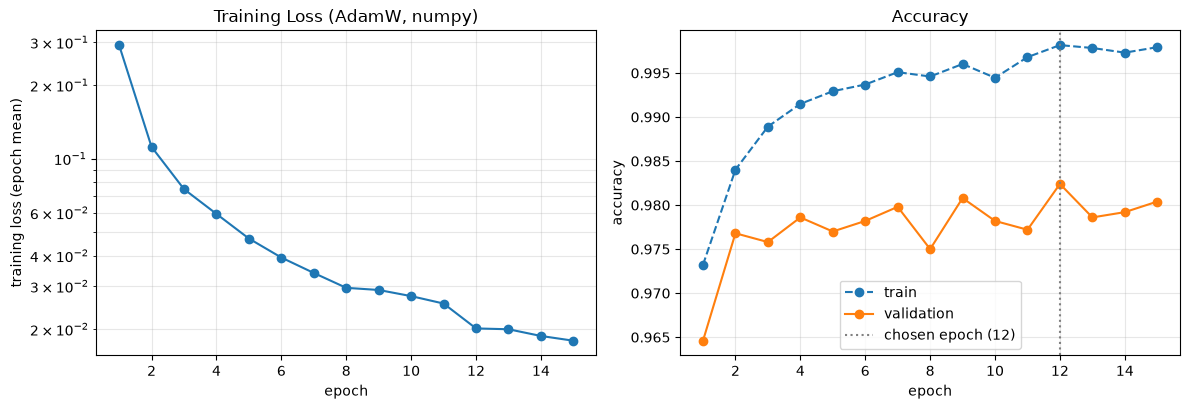

In [8]:
# =====================================================
# Figure
# =====================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, epochs + 1), history["loss"], "o-")
ax[0].set_yscale("log")
ax[0].set(xlabel="epoch", ylabel="training loss (epoch mean)", title="Training Loss (AdamW, numpy)")
ax[0].grid(True, which="both", alpha=0.3)
ax[1].plot(range(1, epochs + 1), history["train"], "o--", label="train")
ax[1].plot(range(1, epochs + 1), history["val"], "o-", label="validation")
ax[1].axvline(best_epoch, color="gray", linestyle=":", label=f"chosen epoch ({best_epoch})")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
ax[1].grid(True, alpha=0.3)
ax[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "numpy_final.png"), dpi=200, bbox_inches="tight")
plt.show()